[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amiguelartiaga-docencia/2627_mlcom_tp2/blob/main/notebooks/ejemplo1_openclip.ipynb)

# Ejemplo 1 — OpenCLIP: textos frente a imágenes

CLIP proyecta textos e imágenes en el mismo espacio. Tras normalizar los vectores, el producto escalar es la similitud coseno: cada texto debería parecerse más a su imagen.

## Instalación y datos (Colab)

La celda siguiente instala los paquetes y clona el repositorio de la práctica (con las imágenes) en `/content`, así que el cuaderno funciona aunque se suba suelto a Colab.

In [ ]:
!pip install open_clip_torch
!git clone https://github.com/amiguelartiaga-docencia/2627_mlcom_tp2.git
%cd /content/2627_mlcom_tp2

## Modelo CLIP

In [2]:
import torch
import open_clip
from PIL import Image
import matplotlib.pyplot as plt

model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
tokenizer = open_clip.get_tokenizer('ViT-B-32')

## Dos imágenes de la colección y cuatro textos

Los dos primeros textos describen la primera imagen y los dos últimos la segunda (este modelo de CLIP está entrenado con textos en inglés).

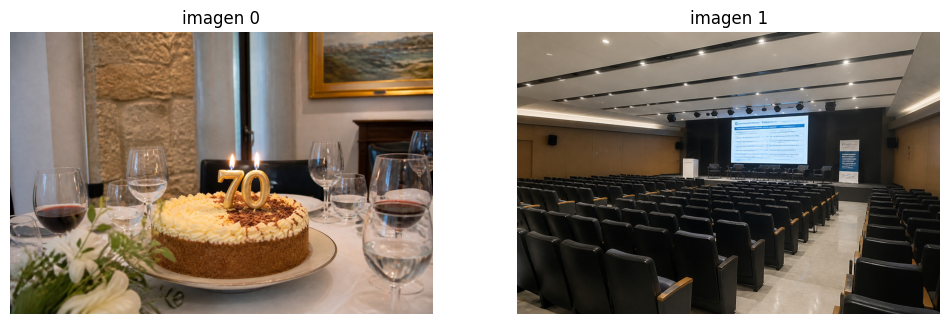

In [3]:
fotos = ['img/fotos/img_bb33d1ee14e1.jpg', 'img/fotos/img_a3788161779f.jpg']

textos = ['a birthday cake with number 70 candles',
          'a dinner table with wine glasses and a cake',
          'an empty conference auditorium',
          'rows of empty seats in front of a projection screen']

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i in range(2):
    ax[i].imshow(Image.open(fotos[i]))
    ax[i].set_title(f'imagen {i}')
    ax[i].axis('off')

## Embeddings, normalización y producto escalar

In [4]:
imagenes = torch.stack([preprocess(Image.open(f)) for f in fotos])

with torch.no_grad():
    emb_img = model.encode_image(imagenes)
    emb_txt = model.encode_text(tokenizer(textos))

emb_img = emb_img / emb_img.norm(dim=-1, keepdim=True)
emb_txt = emb_txt / emb_txt.norm(dim=-1, keepdim=True)

similitud = emb_img @ emb_txt.T
print(emb_img.shape, emb_txt.shape)
print(similitud)

torch.Size([2, 512]) torch.Size([4, 512])
tensor([[0.3133, 0.3172, 0.0517, 0.0123],
        [0.0084, 0.0201, 0.3293, 0.3007]])


## Matriz de similitud

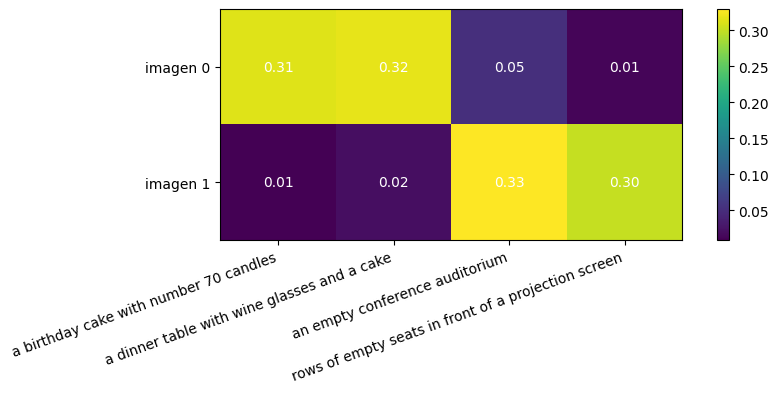

In [5]:
plt.figure(figsize=(9, 3))
plt.imshow(similitud, cmap='viridis')
plt.colorbar()
plt.xticks(range(4), textos, rotation=20, ha='right')
plt.yticks(range(2), ['imagen 0', 'imagen 1'])
for i in range(2):
    for j in range(4):
        plt.text(j, i, f'{similitud[i, j]:.2f}', ha='center', va='center', color='white')
plt.show()